In [1]:
import re
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Source: S. Prahl, "Optical absorption of hemoglobin", omlc.org
text = open("data/prahl_hemoglobin.html", encoding="latin-1").read()
text = re.sub(r"<[^>]+>", " ", text)  # remove HTML tags
rows = re.findall(r"^\s*(\d+)\s+([\d.]+)\s+([\d.]+)\s*$", text, flags=re.M)
data = np.array(rows, dtype=float)
lam, e_hbo2, e_hb = data[:, 0], data[:, 1], data[:, 2]  # nm, cm-1/M, cm-1/M

print(data.shape)
print(data[lam == 660])

(376, 3)
[[ 660.    319.6  3226.56]]


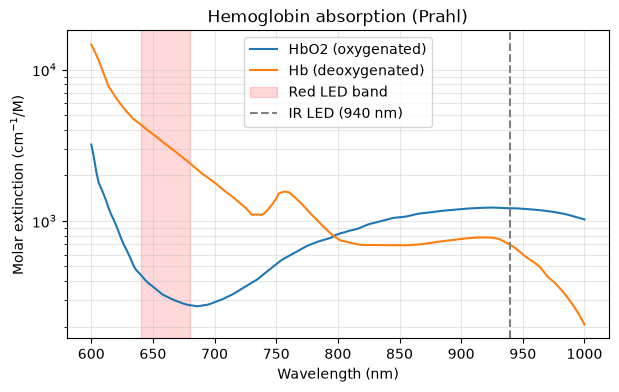

In [3]:
mask = (lam >= 600) & (lam <= 1000)
plt.figure(figsize=(7, 4))
plt.semilogy(lam[mask], e_hbo2[mask], label="HbO2 (oxygenated)")
plt.semilogy(lam[mask], e_hb[mask], label="Hb (deoxygenated)")
plt.axvspan(640, 680, color="red", alpha=0.15, label="Red LED band")
plt.axvline(940, color="gray", linestyle="--", label="IR LED (940 nm)")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Molar extinction (cm$^{-1}$/M)")
plt.title("Hemoglobin absorption (Prahl)")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

In [4]:
def mua_melanin(lam_nm, f_mel):
    """Absorption coefficient of the epidermis (cm^-1), Jacques (2013).
    f_mel: volume fraction of melanosomes, about 0.02 (light skin) to 0.4 (very dark skin)."""
    return f_mel * 6.6e11 * lam_nm**-3.33

print("mu_a at 660 nm, f=0.3:", round(mua_melanin(660, 0.3), 1), "cm-1")
print("mu_a at 940 nm, f=0.3:", round(mua_melanin(940, 0.3), 1), "cm-1")

mu_a at 660 nm, f=0.3: 80.8 cm-1
mu_a at 940 nm, f=0.3: 24.9 cm-1


In [5]:
def led_spectrum(lam_nm, center, fwhm):
    """Gaussian emission spectrum, normalized so that its sum is 1."""
    s = np.exp(-4 * np.log(2) * (lam_nm - center)**2 / fwhm**2)
    return s / s.sum()

In [6]:
d_skin = 0.02  # cm: about 100 um of epidermis, crossed twice (in and out of the finger)

print("FWHM | shift of the red LED (nm) for f_mel = 0.02, 0.1, 0.2, 0.4")
for fwhm in [20, 30, 40]:
    led = led_spectrum(lam, 660, fwhm)
    shifts = []
    for f in [0.02, 0.1, 0.2, 0.4]:
        seen = led * np.exp(-mua_melanin(lam, f) * d_skin)  # Beer-Lambert through the skin
        center = (lam * seen).sum() / seen.sum()             # "center of gravity" of the light
        shifts.append(center - 660)
    print(fwhm, "nm |", "  ".join(f"{s:+.2f}" for s in shifts))

FWHM | shift of the red LED (nm) for f_mel = 0.02, 0.1, 0.2, 0.4
20 nm | +0.04  +0.20  +0.39  +0.78
30 nm | +0.09  +0.44  +0.88  +1.75
40 nm | +0.16  +0.79  +1.56  +3.10


In [7]:
C_HB = 150 / 64500  # hemoglobin concentration in blood (mol/L): 150 g/L / 64,500 g/mol

def mua_blood(S):
    """Absorption coefficient of blood (cm^-1) at saturation S (0 to 1)."""
    return 2.303 * C_HB * (S * e_hbo2 + (1 - S) * e_hb)

def ratio_R(S, f_mel, fwhm_red=20, d_skin=0.02, dd=0.002):
    """Ratio R measured by a virtual oximeter.
    dd: extra blood thickness at each heartbeat (cm)."""
    T_skin = np.exp(-mua_melanin(lam, f_mel) * d_skin)  # skin filter (constant)
    pulse = np.exp(-mua_blood(S) * dd)                  # extra absorption at the heartbeat
    def ac_dc(led):
        dc = (led * T_skin).sum()             # light received between beats
        peak = (led * T_skin * pulse).sum()   # light received at the beat
        return (dc - peak) / dc
    return ac_dc(led_spectrum(lam, 660, fwhm_red)) / ac_dc(led_spectrum(lam, 940, 40))

for S in [1.0, 0.97, 0.90, 0.85, 0.80, 0.70]:
    print(f"S = {S:.2f}  ->  R = {ratio_R(S, 0.02):.3f}")

S = 1.00  ->  R = 0.272
S = 0.97  ->  R = 0.350
S = 0.90  ->  R = 0.539
S = 0.85  ->  R = 0.682
S = 0.80  ->  R = 0.832
S = 0.70  ->  R = 1.154
